# Milestone 2 — Data Pipeline and MLP Networks
### Land Cover Classification from Sentinel-2 Satellite Imagery (EuroSAT)

**Team:** Mohammed Alroomi (202250760) · Abdelrahman Osman (202253120)

This notebook builds a complete, reusable PyTorch pipeline for the EuroSAT RGB dataset
(27,000 Sentinel-2 patches, 64×64 RGB, 10 land-cover classes) and uses it to train and
compare two multilayer perceptrons:

* a **shallow MLP** with two hidden layers, and
* a **deeper MLP** with five hidden layers.

Every stage is written as a self-contained function or class so it can be reused in later
milestones (the CNN and transfer-learning models will plug into the same loaders, loss
factory, optimizer factory and training loop).

| Rubric item | Section |
|---|---|
| Data pipeline (load + show samples, preprocessing, 80/20 test split, 80/20 val split, stratify, DataLoaders, fit on train only) | §1 |
| Flexible MLP with justified width / activation / output layer | §2 |
| Training & evaluation utilities | §3 |
| Three loss functions + regularization strength | §4 |
| Three optimizers | §5 |
| 3 × 3 loss × optimizer comparison (shallow MLP) | §6 |
| Learning-rate study (4 values) | §7 |
| Deeper five-hidden-layer MLP with the optimal settings | §8 |
| Shallow vs deep comparison on the test set | §9 |
| Required loss / accuracy curves for both networks | §10 |

## 0. Setup

All randomness (data split, weight initialisation, mini-batch shuffling, dropout) is driven
by a single seed so every number in this notebook is reproducible.

In [1]:
import os, time, random, copy
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, confusion_matrix, classification_report

SEED = 42
DATA_DIR = os.path.join("..", "data", "raw", "EuroSAT_RGB")   # see README for download
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int = SEED) -> None:
    # Seed every random number generator used in this notebook.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
pd.set_option("display.precision", 4)

# Consistent, readable plot style used for every figure in the notebook.
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e3e3e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.labelsize": 10.5, "legend.frameon": False, "lines.linewidth": 2,
})

print(f"PyTorch {torch.__version__} | device: {DEVICE} | CPU threads: {torch.get_num_threads()}")
print(f"Dataset directory: {DATA_DIR}  (exists: {os.path.isdir(DATA_DIR)})")

PyTorch 2.14.1+cu130 | device: cpu | CPU threads: 2
Dataset directory: ../data/raw/EuroSAT_RGB  (exists: True)


## 1. Data Pipeline

The pipeline is split into small methods, each doing one job, and then composed into a
single `build_data_pipeline(...)` method at the end of this section:

| Step | Method |
|---|---|
| Load images + labels from a class-per-folder dataset | `load_image_folder` |
| Show one sample per class | `show_one_sample_per_class` |
| Stratified train/test, then train/val split | `split_dataset` |
| Reshape, normalise, label-encode, convert to tensors (fitted on train only) | `ImagePreprocessor` |
| Wrap tensors in `DataLoader`s | `make_dataloaders` |

### 1.1 Load the dataset

In [2]:
def load_image_folder(root: str):
    # Load a class-per-subfolder image dataset into memory.
    # Returns X (N, H, W, C) uint8, y (N,) string labels, and the sorted class names.
    class_names = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
    images, labels = [], []
    for name in class_names:
        folder = os.path.join(root, name)
        for fname in sorted(os.listdir(folder)):
            if fname.lower().endswith((".jpg", ".jpeg", ".png", ".tif")):
                with Image.open(os.path.join(folder, fname)) as img:
                    images.append(np.asarray(img.convert("RGB"), dtype=np.uint8))
                labels.append(name)
    return np.stack(images), np.array(labels), class_names

t0 = time.time()
X_raw, y_raw, CLASS_NAMES = load_image_folder(DATA_DIR)
print(f"Loaded {len(X_raw):,} images in {time.time() - t0:.1f}s")
print(f"Image array shape: {X_raw.shape}  dtype: {X_raw.dtype}  pixel range: [{X_raw.min()}, {X_raw.max()}]")

counts = pd.Series(y_raw).value_counts().reindex(CLASS_NAMES)
class_table = pd.DataFrame({"images": counts, "share (%)": (100 * counts / counts.sum()).round(2)})
class_table.loc["TOTAL"] = [counts.sum(), 100.0]
class_table

Loaded 27,000 images in 3.5s
Image array shape: (27000, 64, 64, 3)  dtype: uint8  pixel range: [0, 255]


,images,share (%)
AnnualCrop,3000.0,11.11
Forest,3000.0,11.11
HerbaceousVegetation,3000.0,11.11
Highway,2500.0,9.26
Industrial,2500.0,9.26
Pasture,2000.0,7.41
PermanentCrop,2500.0,9.26
Residential,3000.0,11.11
River,2500.0,9.26
SeaLake,3000.0,11.11


### 1.2 One sample from each class

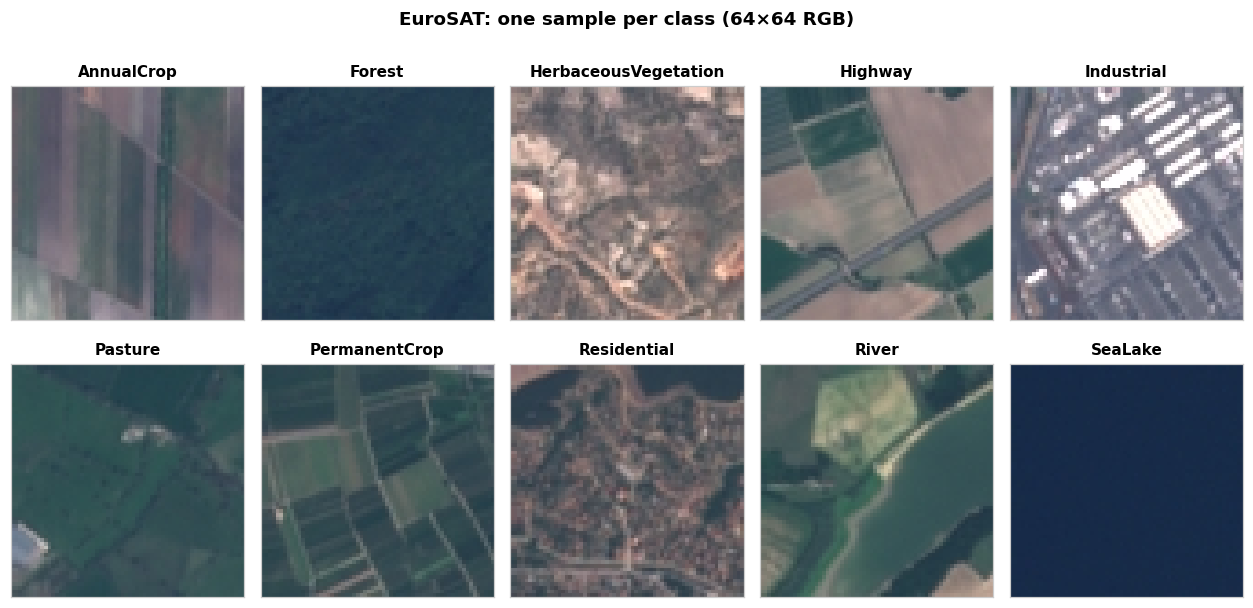

In [3]:
def show_one_sample_per_class(X, y, class_names, seed: int = SEED, ncols: int = 5):
    # Display one randomly chosen image for every class in a grid.
    rng = np.random.default_rng(seed)
    nrows = int(np.ceil(len(class_names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.3 * ncols, 2.85 * nrows))
    for ax, name in zip(axes.ravel(), class_names):
        idx = rng.choice(np.flatnonzero(y == name))
        ax.imshow(X[idx])
        ax.set_title(name, fontsize=10, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(True); spine.set_color("#cccccc")
    for ax in axes.ravel()[len(class_names):]:
        ax.axis("off")
    fig.suptitle("EuroSAT: one sample per class (64×64 RGB)", fontweight="bold", y=1.0)
    fig.tight_layout(h_pad=1.6)
    plt.show()

show_one_sample_per_class(X_raw, y_raw, CLASS_NAMES)

### 1.3 Stratified splits

EuroSAT ships **without a predefined train/test split**, so `split_dataset` falls back to
the required scheme:

1. 80 % train / 20 % **test**, stratified by class;
2. the 80 % train portion is split again 80 % **train** / 20 % **validation**, stratified.

This gives a 64 / 16 / 20 % train / validation / test partition. Stratifying keeps the
mild class imbalance (2,000–3,000 images per class) identical in every split, so the
validation and test scores are not distorted by a split that under-samples a class such as
*Pasture*. The method also accepts predefined split indices, in which case it uses them
instead of creating new ones.

In [4]:
def split_dataset(X, y, test_size=0.20, val_size=0.20, seed=SEED, predefined_split=None):
    # Return a dict with X/y for 'train', 'val' and 'test'.
    # predefined_split: optional dict {'train': idx, 'test': idx} supplied by the dataset.
    # If absent, an 80/20 stratified train/test split is created. The training portion
    # is always split again (80/20, stratified) into train and validation.
    if predefined_split is not None:
        X_trval, y_trval = X[predefined_split["train"]], y[predefined_split["train"]]
        X_test, y_test = X[predefined_split["test"]], y[predefined_split["test"]]
    else:
        X_trval, X_test, y_trval, y_test = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=seed)
    X_train, X_val, y_train, y_val = train_test_split(
        X_trval, y_trval, test_size=val_size, stratify=y_trval, random_state=seed)
    return {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}

splits = split_dataset(X_raw, y_raw)

split_table = pd.DataFrame(
    {name: pd.Series(lbls).value_counts().reindex(CLASS_NAMES) for name, (_, lbls) in splits.items()})
split_table.loc["TOTAL"] = split_table.sum()
for name in splits:
    split_table[f"{name} %"] = (100 * split_table[name] / split_table.loc["TOTAL", name]).round(2)
print("Images per class in each split (the % columns show that every split keeps the same class mix):")
split_table

Images per class in each split (the % columns show that every split keeps the same class mix):


,train,val,test,train %,val %,test %
AnnualCrop,1920,480,600,11.11,11.11,11.11
Forest,1920,480,600,11.11,11.11,11.11
HerbaceousVegetation,1920,480,600,11.11,11.11,11.11
Highway,1600,400,500,9.26,9.26,9.26
Industrial,1600,400,500,9.26,9.26,9.26
Pasture,1280,320,400,7.41,7.41,7.41
PermanentCrop,1600,400,500,9.26,9.26,9.26
Residential,1920,480,600,11.11,11.11,11.11
River,1600,400,500,9.26,9.26,9.26
SeaLake,1920,480,600,11.11,11.11,11.11


### 1.4 Preprocessing — fitted on the training split only

`ImagePreprocessor` follows the scikit-learn `fit` / `transform` pattern so that **every
parameter is learned from the training split only** and then applied unchanged to the
validation and test splits (no information leaks from val/test into training):

* **Reshaping** – each 64×64×3 image is flattened into a 12,288-dimensional vector, since an
  MLP takes a 1-D input.
* **Normalisation** – pixels are scaled to [0, 1] and then standardised with the
  per-channel (R, G, B) mean and standard deviation of the *training* images. Per-channel
  statistics keep the colour balance between channels, which is a strong cue in this dataset
  (e.g. dark-green *Forest* vs bright *Industrial*).
* **Label encoding** – a `LabelEncoder` fitted on the training labels maps class names to
  integers 0–9.
* **Tensor conversion** – features become `float32` tensors and labels `int64` tensors, as
  expected by `nn.Linear` and the classification losses.

In [5]:
class ImagePreprocessor:
    # Flatten + per-channel standardise images and integer-encode labels.

    def fit(self, X_train, y_train):
        pixels = X_train.astype(np.float32) / 255.0
        # accumulate in float64: a float32 sum over ~70 M strided values loses precision
        self.channel_mean_ = pixels.mean(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)  # (3,)
        self.channel_std_ = pixels.std(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)    # (3,)
        self.label_encoder_ = LabelEncoder().fit(y_train)
        self.image_shape_ = X_train.shape[1:]
        return self

    def transform(self, X, y):
        pixels = X.astype(np.float32) / 255.0
        pixels = (pixels - self.channel_mean_) / self.channel_std_      # normalise
        features = pixels.reshape(len(pixels), -1)                     # reshape to vectors
        labels = self.label_encoder_.transform(y)                      # encode labels
        return torch.from_numpy(features), torch.from_numpy(labels).long()   # tensors

    @property
    def classes_(self):
        return list(self.label_encoder_.classes_)


prep = ImagePreprocessor().fit(*splits["train"])
tensors = {name: prep.transform(Xs, ys) for name, (Xs, ys) in splits.items()}

print("Parameters fitted on the TRAINING split only:")
print(f"  channel mean (R, G, B): {np.round(prep.channel_mean_, 4)}")
print(f"  channel std  (R, G, B): {np.round(prep.channel_std_, 4)}")
print(f"  label encoding: {dict((str(c), i) for i, c in enumerate(prep.classes_))}\n")
for name, (Xt, yt) in tensors.items():
    print(f"  {name:<5} X {tuple(Xt.shape)} {Xt.dtype} | y {tuple(yt.shape)} {yt.dtype} | "
          f"feature mean {Xt.mean():+.4f}, std {Xt.std():.4f}")
print("\nTrain features have mean ≈ 0 and std ≈ 1 by construction; val/test are close but not exact,"
      "\nconfirming they were transformed with the training statistics rather than their own.")

Parameters fitted on the TRAINING split only:
  channel mean (R, G, B): [0.3445 0.38   0.4075]
  channel std  (R, G, B): [0.2026 0.1367 0.1152]
  label encoding: {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}



  train X (17280, 12288) torch.float32 | y (17280,) torch.int64 | feature mean -0.0000, std 1.0000
  val   X (4320, 12288) torch.float32 | y (4320,) torch.int64 | feature mean +0.0015, std 1.0036
  test  X (5400, 12288) torch.float32 | y (5400,) torch.int64 | feature mean +0.0062, std 1.0058

Train features have mean ≈ 0 and std ≈ 1 by construction; val/test are close but not exact,
confirming they were transformed with the training statistics rather than their own.


### 1.5 DataLoaders

In [6]:
def make_dataloaders(tensors, batch_size=128):
    # Wrap (features, labels) tensors in DataLoaders. Only the training loader shuffles.
    return {name: DataLoader(TensorDataset(Xt, yt), batch_size=batch_size,
                             shuffle=(name == "train"), num_workers=0)
            for name, (Xt, yt) in tensors.items()}

BATCH_SIZE = 128
loaders = make_dataloaders(tensors, BATCH_SIZE)
xb, yb = next(iter(loaders["train"]))
for name, dl in loaders.items():
    print(f"{name:<5}: {len(dl.dataset):>6,} samples -> {len(dl):>4} batches of up to {BATCH_SIZE}")
print(f"\nOne training batch: inputs {tuple(xb.shape)}, labels {tuple(yb.shape)} -> {yb[:10].tolist()}")

train: 17,280 samples ->  135 batches of up to 128
val  :  4,320 samples ->   34 batches of up to 128
test :  5,400 samples ->   43 batches of up to 128

One training batch: inputs (128, 12288), labels (128,) -> [6, 1, 9, 7, 1, 7, 1, 6, 0, 0]


### 1.6 The complete pipeline as one reusable method

The individual steps above are composed into `build_data_pipeline`, which is what later
milestones will call. Re-running it here reproduces exactly the same splits and loaders.

In [7]:
def build_data_pipeline(root, batch_size=128, test_size=0.20, val_size=0.20,
                        seed=SEED, show_samples=False):
    # Load -> (optionally) show samples -> stratified split -> preprocess (fit on train) -> DataLoaders.
    X, y, class_names = load_image_folder(root)
    if show_samples:
        show_one_sample_per_class(X, y, class_names, seed)
    data_splits = split_dataset(X, y, test_size, val_size, seed)
    preprocessor = ImagePreprocessor().fit(*data_splits["train"])
    data_tensors = {k: preprocessor.transform(*v) for k, v in data_splits.items()}
    return {"loaders": make_dataloaders(data_tensors, batch_size), "tensors": data_tensors,
            "preprocessor": preprocessor, "class_names": preprocessor.classes_,
            "input_dim": data_tensors["train"][0].shape[1]}

pipeline = build_data_pipeline(DATA_DIR, BATCH_SIZE)
assert all(torch.equal(pipeline["tensors"][k][1], tensors[k][1]) for k in tensors)
loaders, INPUT_DIM, N_CLASSES = pipeline["loaders"], pipeline["input_dim"], len(pipeline["class_names"])
del X_raw, splits, tensors   # free the raw copies; everything below uses the pipeline output
print(f"Pipeline rebuilt and verified identical. Input dim = {INPUT_DIM:,}, classes = {N_CLASSES}")

Pipeline rebuilt and verified identical. Input dim = 12,288, classes = 10


## 2. MLP Implementation

`MLP` builds a network of any depth from a list of hidden-layer widths, so the same class
gives both the shallow (2 hidden layers) and the deep (5 hidden layers) model. Each hidden
block is `Linear → BatchNorm → ReLU → Dropout`.

**Number of neurons — shallow MLP: 12,288 → 512 → 256 → 10.**
The input is very wide (12,288 features), so the first layer compresses it by ~24× into 512
units; the second halves it again to 256 before the 10-way output. This funnel shape forces
the network to learn progressively more compact colour/texture features. 512 first-layer
units already give ~6.3 M weights, which is enough capacity to separate ten classes while
keeping training fast on a CPU and limiting overfitting with ~17 k training images. Much
wider layers mostly add parameters to the first layer without improving the representation.

**Activation — ReLU.** ReLU does not saturate for positive inputs, so gradients do not vanish
as they would with sigmoid/tanh, which matters even more in the 5-layer network. It is also
cheap to compute. **BatchNorm** keeps each layer's input distribution stable (allowing the
same learning rate to work for both depths), and **Dropout (p = 0.3)** randomly removes units
during training to reduce overfitting.

**Output layer — 10 linear units (logits) + softmax.** The task is multi-class, single-label
classification, so the output has one unit per class and softmax turns the logits into a
probability distribution that sums to 1. The softmax is applied *inside* the loss
(log-softmax + negative log-likelihood) for numerical stability, and explicitly by
`predict_proba` at inference time.

**Deeper MLP — 12,288 → 512 → 256 → 256 → 128 → 64 → 10.** It keeps the same first two
layers as the shallow network and adds three more, so the comparison in §9 isolates the
effect of depth.

In [8]:
class MLP(nn.Module):
    # Configurable multilayer perceptron for classification.

    def __init__(self, input_dim, hidden_dims, n_classes, dropout=0.3,
                 activation=nn.ReLU, batch_norm=True):
        super().__init__()
        layers, prev = [], input_dim
        for width in hidden_dims:
            layers.append(nn.Linear(prev, width))
            if batch_norm:
                layers.append(nn.BatchNorm1d(width))
            layers.append(activation())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = width
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(prev, n_classes)        # logits, one per class
        self.hidden_dims = list(hidden_dims)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")   # He init suits ReLU
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.classifier(self.features(x))

    @torch.no_grad()
    def predict_proba(self, x):
        return F.softmax(self.forward(x), dim=1)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


SHALLOW_DIMS = [512, 256]
DEEP_DIMS = [512, 256, 256, 128, 64]

for label, dims in [("Shallow MLP (2 hidden layers)", SHALLOW_DIMS), ("Deep MLP (5 hidden layers)", DEEP_DIMS)]:
    m = MLP(INPUT_DIM, dims, N_CLASSES)
    print(f"{label}: {INPUT_DIM} -> {' -> '.join(map(str, dims))} -> {N_CLASSES} | "
          f"{count_parameters(m):,} trainable parameters")
print()
print(MLP(INPUT_DIM, SHALLOW_DIMS, N_CLASSES))

Shallow MLP (2 hidden layers): 12288 -> 512 -> 256 -> 10 | 6,427,402 trainable parameters
Deep MLP (5 hidden layers): 12288 -> 512 -> 256 -> 256 -> 128 -> 64 -> 10 | 6,533,322 trainable parameters

MLP(
  (features): Sequential(
    (0): Linear(in_features=12288, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
  )
  (classifier): Linear(in_features=256, out_features=10, bias=True)
)


## 3. Training and Evaluation Utilities

These methods are shared by every experiment:

* `make_loss(name)` and `make_optimizer(name, ...)` – factories, so experiments are described
  by plain strings (`"focal"`, `"adam"`, …).
* `train_one_epoch` / `evaluate` – one pass over a loader; `evaluate` returns loss, accuracy
  and macro-F1.
* `fit` – trains for a number of epochs, records the full history, and keeps the weights from
  the epoch with the best **validation macro-F1** (checkpoint selection, so the reported model
  is never an over-fitted final epoch).
* `run_experiment` – seeds everything, builds a fresh model, and trains it, so every run starts
  from an identical initialisation and differences are due only to the setting being studied.

**Model-selection metric.** Comparing runs by validation *loss* is not fair here because the
three loss functions are on different scales (focal loss is much smaller than cross-entropy by
design). We therefore select on **validation macro-F1** – the project's validation metric from
Milestone 1, which weighs all ten classes equally despite the 2,000–3,000-image imbalance – and
also report validation accuracy. Training metrics are averaged over the mini-batches of each
epoch (with dropout active), which is why early-epoch training accuracy can sit below
validation accuracy.

In [9]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, n, preds, targets = 0.0, 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += loss_fn(logits, yb).item() * len(yb)
        preds.append(logits.argmax(1).cpu()); targets.append(yb.cpu())
        n += len(yb)
    preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return {"loss": total_loss / n, "acc": (preds == targets).mean(),
            "macro_f1": f1_score(targets, preds, average="macro"),
            "preds": preds, "targets": targets}


def fit(model, loaders, loss_fn, optimizer, epochs, verbose=False):
    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]}
    best = {"val_f1": -1.0}
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, loaders["train"], loss_fn, optimizer)
        val = evaluate(model, loaders["val"], loss_fn)
        for key, value in zip(history, [tr_loss, tr_acc, val["loss"], val["acc"], val["macro_f1"]]):
            history[key].append(value)
        if val["macro_f1"] > best["val_f1"]:
            best = {"epoch": epoch, "val_f1": val["macro_f1"], "val_acc": val["acc"],
                    "val_loss": val["loss"], "state": copy.deepcopy(model.state_dict())}
        if verbose and (epoch == 1 or epoch % 5 == 0 or epoch == epochs):
            print(f"epoch {epoch:>2}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {val['loss']:.4f} acc {val['acc']:.4f} macro-F1 {val['macro_f1']:.4f}")
    model.load_state_dict(best.pop("state"))      # restore best-validation weights
    best["train_time_s"] = time.time() - start
    return history, best

## 4. Loss Functions

Three classification losses are compared:

| Loss | Formula (per sample, true class *t*) | Why it is a sensible choice here |
|---|---|---|
| **Cross-entropy (CE)** | −log p<sub>t</sub> | The standard maximum-likelihood loss for softmax classifiers; the baseline. |
| **CE + label smoothing (ε = 0.1)** | CE against a target of 1 − ε on the true class and ε / (K−1) spread over the others | Stops the network from becoming over-confident. Useful because several EuroSAT classes look alike at 64×64 (AnnualCrop / PermanentCrop, Forest / HerbaceousVegetation, Highway / River). |
| **Focal loss (γ = 2)** | −(1 − p<sub>t</sub>)<sup>γ</sup> log p<sub>t</sub> | Down-weights easy, well-classified samples and focuses learning on hard, confusable ones; designed for imbalance and hard examples. |

PyTorch has no built-in multi-class focal loss, so it is implemented below.

In [10]:
class FocalLoss(nn.Module):
    # Multi-class focal loss (Lin et al., 2017): FL = -alpha_t * (1 - p_t)^gamma * log(p_t).

    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha            # optional per-class weights (tensor of shape [K])

    def forward(self, logits, target):
        log_p = F.log_softmax(logits, dim=1)
        log_p_t = log_p.gather(1, target.unsqueeze(1)).squeeze(1)
        p_t = log_p_t.exp()
        loss = -((1.0 - p_t) ** self.gamma) * log_p_t
        if self.alpha is not None:
            loss = loss * self.alpha.to(logits.device)[target]
        return loss.mean()


LABEL_SMOOTHING, FOCAL_GAMMA = 0.1, 2.0
LOSS_NAMES = {"ce": "Cross-entropy", "ce_ls": "CE + label smoothing", "focal": "Focal loss"}

def make_loss(name):
    if name == "ce":
        return nn.CrossEntropyLoss()
    if name == "ce_ls":
        return nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    if name == "focal":
        return FocalLoss(gamma=FOCAL_GAMMA)
    raise ValueError(f"unknown loss '{name}'")

# Sanity check: the three losses on a confident-correct, an uncertain, and a wrong prediction.
demo_logits = torch.tensor([[4.0, 0.0, 0.0], [1.0, 0.5, 0.0], [0.0, 3.0, 0.0]])
demo_target = torch.tensor([0, 0, 0])
demo = pd.DataFrame({LOSS_NAMES[n]: [make_loss(n)(demo_logits[i:i+1], demo_target[i:i+1]).item() for i in range(3)]
                     for n in LOSS_NAMES},
                    index=["confident & correct", "uncertain & correct", "confident & wrong"])
print("Per-sample loss values on a 3-class toy example (note how focal loss nearly ignores the easy sample):")
demo.round(4)

Per-sample loss values on a 3-class toy example (note how focal loss nearly ignores the easy sample):

,Cross-entropy,CE + label smoothing,Focal loss
confident & correct,0.0360,0.3026,0.0000
uncertain & correct,0.6803,0.7303,0.1657
confident & wrong,3.0949,2.9949,2.8210


### 4.1 Regularization strength

Besides dropout (p = 0.3) and the loss-specific settings above (label smoothing ε = 0.1,
focal γ = 2), every experiment applies **L2 regularization through the optimizer's
`weight_decay`**. To choose its strength we run a short check with the shallow MLP, the
baseline cross-entropy loss and Adam (learning rate 1e-3, 10 epochs) for three candidate
values and keep the one with the highest validation macro-F1. The selected value is then
fixed for all later experiments, so it does not confound the loss/optimizer comparison.

In [11]:
DEFAULT_LR = {"sgd": 1e-2, "rmsprop": 1e-3, "adam": 1e-3}
OPT_NAMES = {"sgd": "SGD + momentum", "rmsprop": "RMSprop", "adam": "Adam"}

def make_optimizer(name, params, lr, weight_decay):
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, alpha=0.99, weight_decay=weight_decay)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, betas=(0.9, 0.999), weight_decay=weight_decay)
    raise ValueError(f"unknown optimizer '{name}'")


def run_experiment(hidden_dims, loss_name, opt_name, lr, weight_decay, epochs,
                   loaders=None, seed=SEED, verbose=False):
    # Seed -> fresh model -> train -> return (model, history, best-epoch summary).
    loaders = loaders if loaders is not None else globals()["loaders"]
    set_seed(seed)
    model = MLP(INPUT_DIM, hidden_dims, N_CLASSES).to(DEVICE)
    loss_fn = make_loss(loss_name)
    optimizer = make_optimizer(opt_name, model.parameters(), lr, weight_decay)
    history, best = fit(model, loaders, loss_fn, optimizer, epochs, verbose)
    best.update({"final_train_acc": history["train_acc"][-1], "params": count_parameters(model)})
    return model, history, best


WD_CANDIDATES, WD_EPOCHS = [0.0, 1e-4, 1e-3], 10
wd_rows = []
for wd in WD_CANDIDATES:
    _, hist, best = run_experiment(SHALLOW_DIMS, "ce", "adam", 1e-3, wd, WD_EPOCHS)
    wd_rows.append({"weight_decay": wd, "best val macro-F1": best["val_f1"], "val accuracy": best["val_acc"],
                    "best epoch": best["epoch"], "final train acc": best["final_train_acc"],
                    "train–val acc gap": best["final_train_acc"] - hist["val_acc"][-1]})
    print(f"weight_decay={wd:<7g} best val macro-F1 {best['val_f1']:.4f} (epoch {best['epoch']}) "
          f"[{best['train_time_s']:.0f}s]")

wd_table = pd.DataFrame(wd_rows)
WEIGHT_DECAY = float(wd_table.loc[wd_table["best val macro-F1"].idxmax(), "weight_decay"])
print(f"\n>>> Selected regularization strength: weight_decay (L2) = {WEIGHT_DECAY:g}")
wd_table

weight_decay=0       best val macro-F1 0.6446 (epoch 10) [43s]


weight_decay=0.0001  best val macro-F1 0.6322 (epoch 10) [47s]


weight_decay=0.001   best val macro-F1 0.6162 (epoch 9) [66s]

>>> Selected regularization strength: weight_decay (L2) = 0


,weight_decay,best val macro-F1,val accuracy,best epoch,final train acc,train–val acc gap
0,0.0000,0.6446,0.6556,10,0.6914,0.0359
1,0.0001,0.6322,0.6435,10,0.6715,0.0280
2,0.0010,0.6162,0.6243,9,0.6192,0.0197


**Selected regularization strength: L2 `weight_decay` = 0**, with dropout (p = 0.3) as the active
regularizer. Validation macro-F1 fell as weight decay increased (0.645 → 0.632 → 0.616): dropout
and BatchNorm already keep over-fitting in check over this budget, so extra L2 mainly slowed learning.

## 5. Optimizers

| Optimizer | Settings | Default learning rate for the 3 × 3 comparison |
|---|---|---|
| **SGD with momentum** | momentum 0.9 | 1e-2 |
| **RMSprop** | α = 0.99 | 1e-3 |
| **Adam** | β = (0.9, 0.999) | 1e-3 |

All three use the weight decay selected in §4.1. Each optimizer gets its own standard default
learning rate in the 3 × 3 comparison: plain SGD takes steps directly proportional to the
gradient and needs a roughly 10× larger rate than the adaptive methods, which rescale each
step by a running gradient magnitude. Using a single shared rate would unfairly cripple one
family before the comparison starts. The learning rate itself is then tuned in §7.

In [12]:
pd.DataFrame([{"optimizer": OPT_NAMES[k], "learning rate": DEFAULT_LR[k], "weight decay": WEIGHT_DECAY,
               "torch class": type(make_optimizer(k, [nn.Parameter(torch.zeros(1))], DEFAULT_LR[k], WEIGHT_DECAY)).__name__}
              for k in OPT_NAMES])

,optimizer,learning rate,weight decay,torch class
0,SGD + momentum,0.010,0.0,SGD
1,RMSprop,0.001,0.0,RMSprop
2,Adam,0.001,0.0,Adam


## 6. 3 × 3 Comparison: Loss Functions × Optimizers (shallow MLP)

All nine combinations are trained with the shallow MLP for the same budget (15 epochs), the
same seed and therefore the same initial weights, the same batch size and the same weight
decay. Each run keeps its best-validation epoch.

In [13]:
GRID_EPOCHS = 15
grid_rows, grid_histories = [], {}
for loss_name in LOSS_NAMES:
    for opt_name in OPT_NAMES:
        _, hist, best = run_experiment(SHALLOW_DIMS, loss_name, opt_name, DEFAULT_LR[opt_name],
                                       WEIGHT_DECAY, GRID_EPOCHS)
        grid_histories[(loss_name, opt_name)] = hist
        grid_rows.append({"loss": LOSS_NAMES[loss_name], "optimizer": OPT_NAMES[opt_name],
                          "lr": DEFAULT_LR[opt_name], "best val macro-F1": best["val_f1"],
                          "val accuracy": best["val_acc"], "best epoch": best["epoch"],
                          "final train acc": best["final_train_acc"], "time (s)": round(best["train_time_s"]),
                          "_loss": loss_name, "_opt": opt_name})
        print(f"{LOSS_NAMES[loss_name]:<22} x {OPT_NAMES[opt_name]:<15} -> val macro-F1 {best['val_f1']:.4f}, "
              f"acc {best['val_acc']:.4f} (best epoch {best['epoch']})")

grid_table = (pd.DataFrame(grid_rows).sort_values("best val macro-F1", ascending=False)
              .reset_index(drop=True))
grid_table.index = grid_table.index + 1
grid_table.index.name = "rank"
BEST_LOSS, BEST_OPT = grid_table.loc[1, "_loss"], grid_table.loc[1, "_opt"]
print(f"\n>>> Best combination: {LOSS_NAMES[BEST_LOSS]} + {OPT_NAMES[BEST_OPT]} "
      f"(val macro-F1 {grid_table.loc[1, 'best val macro-F1']:.4f})")
grid_table.drop(columns=["_loss", "_opt"])

Cross-entropy          x SGD + momentum  -> val macro-F1 0.6480, acc 0.6551 (best epoch 15)


Cross-entropy          x RMSprop         -> val macro-F1 0.6527, acc 0.6593 (best epoch 13)


Cross-entropy          x Adam            -> val macro-F1 0.6446, acc 0.6556 (best epoch 10)


CE + label smoothing   x SGD + momentum  -> val macro-F1 0.6468, acc 0.6523 (best epoch 12)


CE + label smoothing   x RMSprop         -> val macro-F1 0.6564, acc 0.6597 (best epoch 13)


CE + label smoothing   x Adam            -> val macro-F1 0.6528, acc 0.6576 (best epoch 15)


Focal loss             x SGD + momentum  -> val macro-F1 0.6455, acc 0.6565 (best epoch 13)


Focal loss             x RMSprop         -> val macro-F1 0.6616, acc 0.6683 (best epoch 13)


Focal loss             x Adam            -> val macro-F1 0.6486, acc 0.6535 (best epoch 15)

>>> Best combination: Focal loss + RMSprop (val macro-F1 0.6616)


,loss,optimizer,lr,best val macro-F1,val accuracy,best epoch,final train acc,time (s)
rank,,,,,,,,
1,Focal loss,RMSprop,0.001,0.6616,0.6683,13,0.7321,59
2,CE + label smoothing,RMSprop,0.001,0.6564,0.6597,13,0.7563,58
3,CE + label smoothing,Adam,0.001,0.6528,0.6576,15,0.7387,85
4,Cross-entropy,RMSprop,0.001,0.6527,0.6593,13,0.7460,60
5,Focal loss,Adam,0.001,0.6486,0.6535,15,0.7152,70
6,Cross-entropy,SGD + momentum,0.010,0.6480,0.6551,15,0.7075,52
7,CE + label smoothing,SGD + momentum,0.010,0.6468,0.6523,12,0.7163,53
8,Focal loss,SGD + momentum,0.010,0.6455,0.6565,13,0.7005,53
9,Cross-entropy,Adam,0.001,0.6446,0.6556,10,0.7288,85


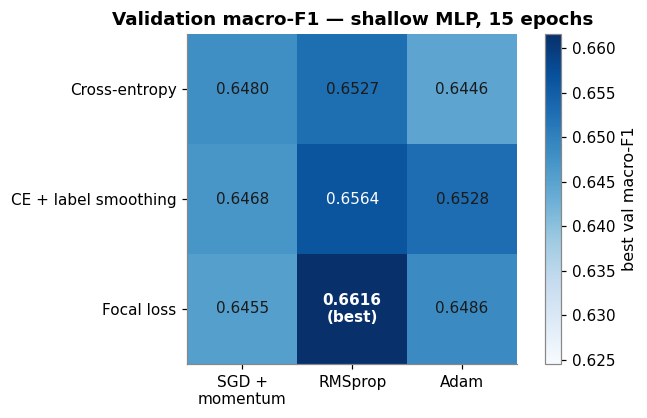

In [14]:
def plot_metric_heatmap(table, value_col, title):
    pivot = (table.pivot(index="loss", columns="optimizer", values=value_col)
             .reindex(index=list(LOSS_NAMES.values()), columns=list(OPT_NAMES.values())))
    fig, ax = plt.subplots(figsize=(7.2, 3.9))
    im = ax.imshow(pivot.values, cmap="Blues", vmin=pivot.values.min() - 0.02, vmax=pivot.values.max())
    ax.set_xticks(range(pivot.shape[1]), [c.replace(" + ", " +\n") for c in pivot.columns])
    ax.set_yticks(range(pivot.shape[0]), pivot.index)
    ax.grid(False)
    best_rc = np.unravel_index(np.nanargmax(pivot.values), pivot.shape)
    for r in range(pivot.shape[0]):
        for c in range(pivot.shape[1]):
            v = pivot.values[r, c]
            dark = v > pivot.values.min() + 0.6 * (pivot.values.max() - pivot.values.min())
            ax.text(c, r, f"{v:.4f}" + ("\n(best)" if (r, c) == best_rc else ""), ha="center", va="center",
                    fontsize=10, fontweight="bold" if (r, c) == best_rc else "normal",
                    color="white" if dark else "#1a1a1a")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=value_col)
    fig.tight_layout()
    plt.show()

plot_metric_heatmap(grid_table, "best val macro-F1", "Validation macro-F1 — shallow MLP, 15 epochs")

**3 × 3 results.** All nine combinations score within 1.7 points of each other (macro-F1
0.645 – 0.662), and RMSprop is the best optimizer for every loss. **Focal loss + RMSprop is
selected** (val macro-F1 0.662, accuracy 0.668): focal loss puts more weight on hard, confusable
classes such as Highway/River, which is exactly what macro-F1 rewards.

## 7. Learning-Rate Study (best loss + optimizer)

Using the winning loss–optimizer pair from §6, four learning rates are evaluated. The four
values bracket the optimizer's default rate (0.1×, 0.3×, 1× and 3×), covering a range wide
enough to show both too-slow and unstable training. All other settings are unchanged.

In [15]:
LR_CANDIDATES = {"sgd": [1e-3, 3e-3, 1e-2, 3e-2], "rmsprop": [1e-4, 3e-4, 1e-3, 3e-3],
                 "adam": [1e-4, 3e-4, 1e-3, 3e-3]}[BEST_OPT]
LR_EPOCHS = 15
lr_rows, lr_histories = [], {}
for lr in LR_CANDIDATES:
    _, hist, best = run_experiment(SHALLOW_DIMS, BEST_LOSS, BEST_OPT, lr, WEIGHT_DECAY, LR_EPOCHS)
    lr_histories[lr] = hist
    lr_rows.append({"learning rate": lr, "best val macro-F1": best["val_f1"], "val accuracy": best["val_acc"],
                    "best epoch": best["epoch"], "final train acc": best["final_train_acc"],
                    "time (s)": round(best["train_time_s"])})
    print(f"lr={lr:<7g} -> val macro-F1 {best['val_f1']:.4f}, acc {best['val_acc']:.4f} (best epoch {best['epoch']})")

lr_table = pd.DataFrame(lr_rows)
BEST_LR = float(lr_table.loc[lr_table["best val macro-F1"].idxmax(), "learning rate"])
print(f"\n>>> Best learning rate for {LOSS_NAMES[BEST_LOSS]} + {OPT_NAMES[BEST_OPT]}: {BEST_LR:g}")
lr_table

lr=0.0001  -> val macro-F1 0.6457, acc 0.6525 (best epoch 13)


lr=0.0003  -> val macro-F1 0.6571, acc 0.6648 (best epoch 13)


lr=0.001   -> val macro-F1 0.6616, acc 0.6683 (best epoch 13)


lr=0.003   -> val macro-F1 0.6583, acc 0.6581 (best epoch 14)

>>> Best learning rate for Focal loss + RMSprop: 0.001


,learning rate,best val macro-F1,val accuracy,best epoch,final train acc,time (s)
0,0.0001,0.6457,0.6525,13,0.6917,64
1,0.0003,0.6571,0.6648,13,0.7159,61
2,0.0010,0.6616,0.6683,13,0.7321,60
3,0.0030,0.6583,0.6581,14,0.7281,62


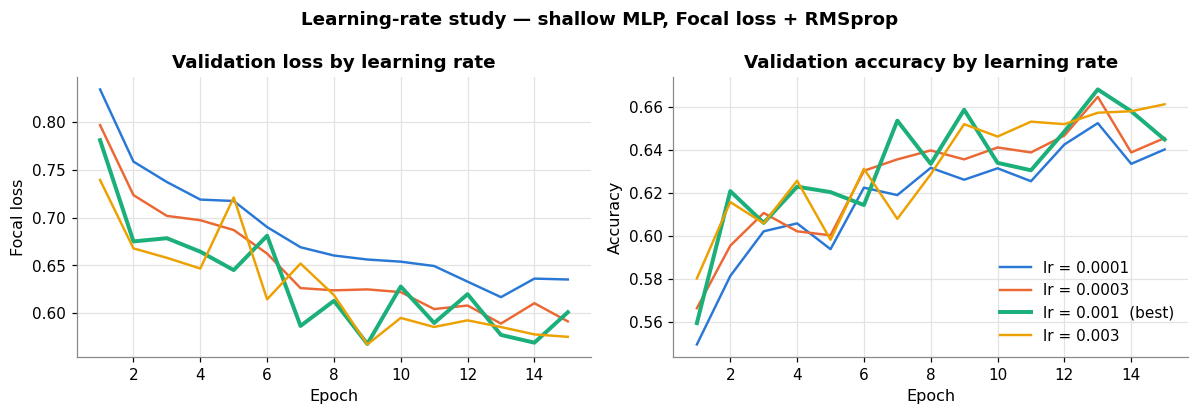

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for color, (lr, hist) in zip(SERIES_COLORS, lr_histories.items()):
    epochs = range(1, len(hist["val_acc"]) + 1)
    lw = 2.6 if lr == BEST_LR else 1.6
    label = f"lr = {lr:g}" + ("  (best)" if lr == BEST_LR else "")
    axes[0].plot(epochs, hist["val_loss"], color=color, lw=lw, label=label)
    axes[1].plot(epochs, hist["val_acc"], color=color, lw=lw, label=label)
axes[0].set(title="Validation loss by learning rate", xlabel="Epoch", ylabel=f"{LOSS_NAMES[BEST_LOSS]}")
axes[1].set(title="Validation accuracy by learning rate", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend(loc="lower right")
fig.suptitle(f"Learning-rate study — shallow MLP, {LOSS_NAMES[BEST_LOSS]} + {OPT_NAMES[BEST_OPT]}",
             fontweight="bold")
fig.tight_layout()
plt.show()

**Learning-rate results.** Validation macro-F1 peaks at the default rate of **1e-3** (0.662):
1e-4 learns too slowly (0.646) and 3e-3 becomes noisier (0.658). 1e-3 is kept for the final models.

## 8. Final Training with the Optimal Settings

Both networks are now trained with the optimal loss, optimizer, learning rate and weight
decay found above, for a longer budget (40 epochs) so their learning curves can be compared.
The shallow MLP is retrained under exactly the same conditions as the deep one, so the only
difference between the two runs is depth. Each model keeps the weights of its best
validation epoch.

In [17]:
FINAL_EPOCHS = 40
OPTIMAL = {"loss": BEST_LOSS, "optimizer": BEST_OPT, "lr": BEST_LR, "weight_decay": WEIGHT_DECAY}
print("Optimal configuration:", {"loss": LOSS_NAMES[BEST_LOSS], "optimizer": OPT_NAMES[BEST_OPT],
                                 "learning rate": BEST_LR, "weight decay": WEIGHT_DECAY,
                                 "batch size": BATCH_SIZE, "epochs": FINAL_EPOCHS})

print("\n--- Shallow MLP (2 hidden layers) ---")
shallow_model, shallow_hist, shallow_best = run_experiment(
    SHALLOW_DIMS, BEST_LOSS, BEST_OPT, BEST_LR, WEIGHT_DECAY, FINAL_EPOCHS, verbose=True)
print(f"best epoch {shallow_best['epoch']} | val macro-F1 {shallow_best['val_f1']:.4f} | "
      f"{shallow_best['train_time_s']:.0f}s")

Optimal configuration: {'loss': 'Focal loss', 'optimizer': 'RMSprop', 'learning rate': 0.001, 'weight decay': 0.0, 'batch size': 128, 'epochs': 40}

--- Shallow MLP (2 hidden layers) ---


epoch  1/40 | train loss 1.0397 acc 0.4635 | val loss 0.7813 acc 0.5593 macro-F1 0.5453


epoch  5/40 | train loss 0.6341 acc 0.6231 | val loss 0.6451 acc 0.6204 macro-F1 0.6029


epoch 10/40 | train loss 0.4908 acc 0.6852 | val loss 0.6279 acc 0.6340 macro-F1 0.6237


epoch 15/40 | train loss 0.3939 acc 0.7321 | val loss 0.6009 acc 0.6449 macro-F1 0.6337


epoch 20/40 | train loss 0.3223 acc 0.7727 | val loss 0.6008 acc 0.6699 macro-F1 0.6610


epoch 25/40 | train loss 0.2714 acc 0.7993 | val loss 0.6108 acc 0.6824 macro-F1 0.6737


epoch 30/40 | train loss 0.2271 acc 0.8265 | val loss 0.6415 acc 0.6734 macro-F1 0.6646


epoch 35/40 | train loss 0.2038 acc 0.8382 | val loss 0.6481 acc 0.6669 macro-F1 0.6591


epoch 40/40 | train loss 0.1850 acc 0.8549 | val loss 0.6427 acc 0.6843 macro-F1 0.6765
best epoch 40 | val macro-F1 0.6765 | 171s


In [18]:
print("--- Deep MLP (5 hidden layers) ---")
deep_model, deep_hist, deep_best = run_experiment(
    DEEP_DIMS, BEST_LOSS, BEST_OPT, BEST_LR, WEIGHT_DECAY, FINAL_EPOCHS, verbose=True)
print(f"best epoch {deep_best['epoch']} | val macro-F1 {deep_best['val_f1']:.4f} | "
      f"{deep_best['train_time_s']:.0f}s")

--- Deep MLP (5 hidden layers) ---


epoch  1/40 | train loss 1.2706 acc 0.3503 | val loss 0.8904 acc 0.5359 macro-F1 0.5197


epoch  5/40 | train loss 0.7823 acc 0.5550 | val loss 0.6714 acc 0.6060 macro-F1 0.5901


epoch 10/40 | train loss 0.6258 acc 0.6273 | val loss 0.6071 acc 0.6377 macro-F1 0.6222


epoch 15/40 | train loss 0.5407 acc 0.6614 | val loss 0.6125 acc 0.6336 macro-F1 0.6293


epoch 20/40 | train loss 0.4792 acc 0.6858 | val loss 0.5936 acc 0.6549 macro-F1 0.6450


epoch 25/40 | train loss 0.4240 acc 0.7115 | val loss 0.6392 acc 0.6426 macro-F1 0.6425


epoch 30/40 | train loss 0.3764 acc 0.7318 | val loss 0.6184 acc 0.6528 macro-F1 0.6451


epoch 35/40 | train loss 0.3381 acc 0.7476 | val loss 0.6283 acc 0.6683 macro-F1 0.6611


epoch 40/40 | train loss 0.3156 acc 0.7595 | val loss 0.6696 acc 0.6477 macro-F1 0.6437
best epoch 37 | val macro-F1 0.6679 | 234s


## 9. Shallow vs Deep: Test-Set Comparison

The held-out test split (5,400 images) is used **only here**, once per model, after all
choices were made on the validation split.

In [19]:
loss_fn = make_loss(BEST_LOSS)
test_results = {"Shallow MLP": evaluate(shallow_model, loaders["test"], loss_fn),
                "Deep MLP": evaluate(deep_model, loaders["test"], loss_fn)}
model_info = {"Shallow MLP": (SHALLOW_DIMS, shallow_best, shallow_hist),
              "Deep MLP": (DEEP_DIMS, deep_best, deep_hist)}

comparison = pd.DataFrame({
    name: {"hidden layers": len(dims), "architecture": " → ".join(map(str, dims)),
           "trainable params": f"{best['params']:,}", "best epoch": best["epoch"],
           "training time (s)": round(best["train_time_s"]),
           "train accuracy (best epoch)": round(hist["train_acc"][best["epoch"] - 1], 4),
           "val macro-F1": round(best["val_f1"], 4),
           "test loss": round(test_results[name]["loss"], 4),
           "test accuracy": round(test_results[name]["acc"], 4),
           "test macro-F1": round(test_results[name]["macro_f1"], 4)}
    for name, (dims, best, hist) in model_info.items()})
comparison

,Shallow MLP,Deep MLP
hidden layers,2,5
architecture,512 → 256,512 → 256 → 256 → 128 → 64
trainable params,"6,427,402","6,533,322"
best epoch,40,37
training time (s),171,234
train accuracy (best epoch),0.8549,0.7583
val macro-F1,0.6765,0.6679
test loss,0.6387,0.6411
test accuracy,0.6867,0.6693
test macro-F1,0.6812,0.662


In [20]:
per_class = pd.DataFrame({
    name: f1_score(res["targets"], res["preds"], average=None) for name, res in test_results.items()},
    index=pipeline["class_names"])
per_class["difference (deep − shallow)"] = per_class["Deep MLP"] - per_class["Shallow MLP"]
per_class.loc["macro average"] = per_class.mean()
print("Per-class test F1-score:")
per_class.round(4)

Per-class test F1-score:


,Shallow MLP,Deep MLP,difference (deep − shallow)
AnnualCrop,0.6650,0.6291,-0.0360
Forest,0.8500,0.8542,0.0042
HerbaceousVegetation,0.6009,0.5882,-0.0127
Highway,0.4507,0.3732,-0.0776
Industrial,0.8409,0.8187,-0.0222
Pasture,0.7514,0.7386,-0.0128
PermanentCrop,0.4912,0.5180,0.0268
Residential,0.6266,0.6220,-0.0046
River,0.6705,0.6260,-0.0445
SeaLake,0.8644,0.8517,-0.0127


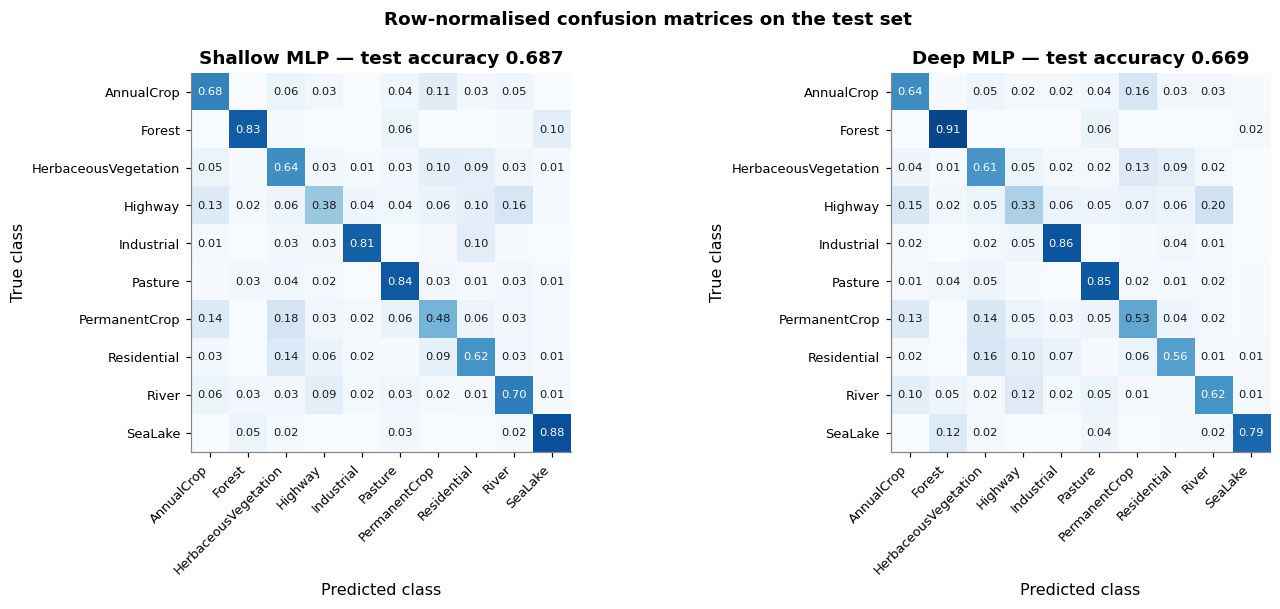

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, (name, res) in zip(axes, test_results.items()):
    cm = confusion_matrix(res["targets"], res["preds"], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    ticks = range(N_CLASSES)
    ax.set_xticks(ticks, pipeline["class_names"], rotation=45, ha="right", fontsize=8.5)
    ax.set_yticks(ticks, pipeline["class_names"], fontsize=8.5)
    for i in ticks:
        for j in ticks:
            if cm[i, j] >= 0.01:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                        color="white" if cm[i, j] > 0.55 else "#1a1a1a")
    ax.set(title=f"{name} — test accuracy {res['acc']:.3f}", xlabel="Predicted class", ylabel="True class")
fig.suptitle("Row-normalised confusion matrices on the test set", fontweight="bold")
fig.tight_layout()
plt.show()

**Shallow vs deep — discussion.**

| | Shallow (2 hidden) | Deep (5 hidden) |
|---|---|---|
| Test accuracy | **0.687** | 0.669 |
| Test macro-F1 | **0.681** | 0.662 |
| Trainable parameters | 6.43 M | 6.53 M |
| Training time (40 epochs) | **171 s** | 234 s |

The shallow MLP is more accurate on the test set (+1.7 accuracy and +1.9 macro-F1 points), better
on 8 of the 10 classes, and faster to train. Both models have almost the same parameter count
because 96–98 % of the weights sit in the first layer, so the extra layers add depth without useful
capacity. Both fail on shape-defined classes (Highway is mistaken for River, PermanentCrop for
HerbaceousVegetation) because a flattened image loses the spatial structure that more layers cannot
recover.

## 10. Required Plots — Learning Curves with the Optimal Settings

For each network: training and validation **loss** versus epoch, and training and
validation **accuracy** versus epoch. The dotted line marks the best-validation epoch whose
weights were kept.

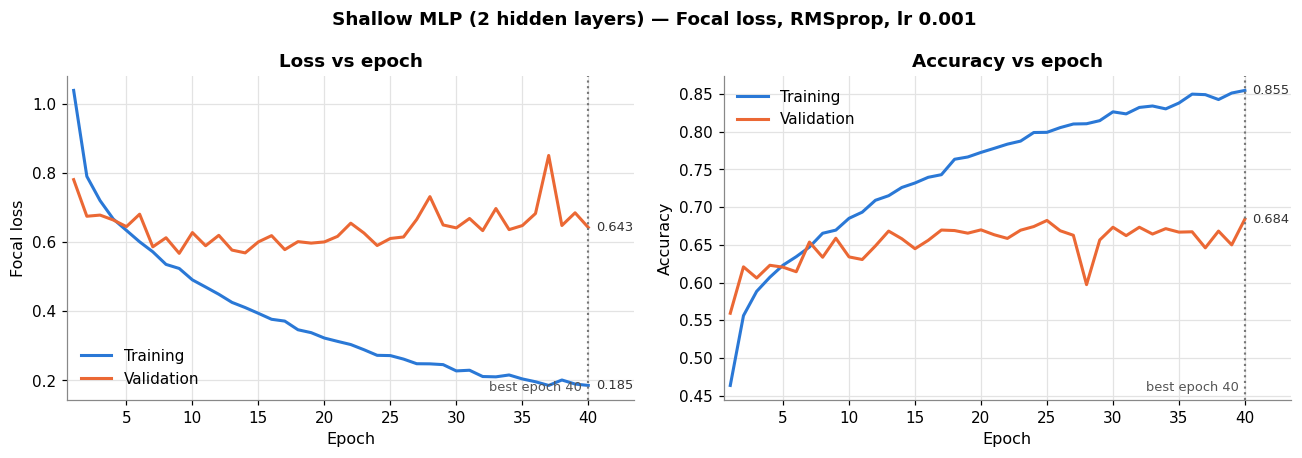

In [22]:
def plot_learning_curves(history, best_epoch, title, loss_label):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.2))
    panels = [(ax_loss, "loss", loss_label, "Loss vs epoch"), (ax_acc, "acc", "Accuracy", "Accuracy vs epoch")]
    for ax, key, ylabel, subtitle in panels:
        ax.plot(epochs, history[f"train_{key}"], color=TRAIN_COLOR, label="Training")
        ax.plot(epochs, history[f"val_{key}"], color=VAL_COLOR, label="Validation")
        ax.axvline(best_epoch, color="#777777", ls=":", lw=1.4)
        ax.annotate(f"best epoch {best_epoch}", xy=(best_epoch, ax.get_ylim()[0]), xytext=(-4, 6),
                    textcoords="offset points", fontsize=8.5, color="#555555", ha="right")
        # direct end-of-line labels so identity is not carried by colour alone
        for series, color in [("train", TRAIN_COLOR), ("val", VAL_COLOR)]:
            ax.annotate(f"{history[f'{series}_{key}'][-1]:.3f}", xy=(epochs[-1], history[f"{series}_{key}"][-1]),
                        xytext=(5, 0), textcoords="offset points", va="center", fontsize=8.5, color="#333333")
        ax.set(title=subtitle, xlabel="Epoch", ylabel=ylabel, xlim=(0.5, epochs[-1] + 3.5))
        ax.legend(loc="best")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    plt.show()

plot_learning_curves(shallow_hist, shallow_best["epoch"],
                     f"Shallow MLP (2 hidden layers) — {LOSS_NAMES[BEST_LOSS]}, {OPT_NAMES[BEST_OPT]}, lr {BEST_LR:g}",
                     LOSS_NAMES[BEST_LOSS])

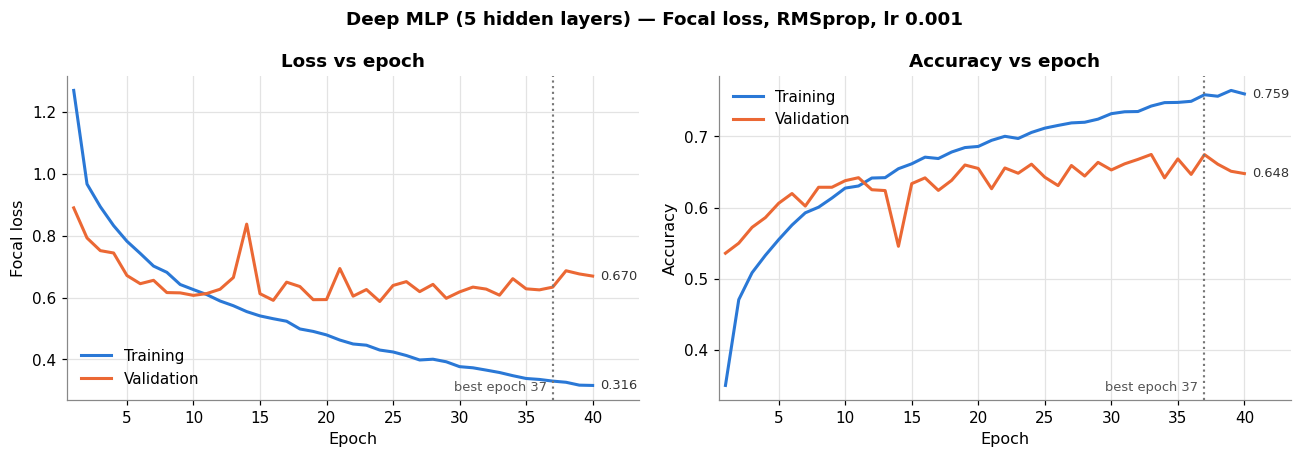

In [23]:
plot_learning_curves(deep_hist, deep_best["epoch"],
                     f"Deep MLP (5 hidden layers) — {LOSS_NAMES[BEST_LOSS]}, {OPT_NAMES[BEST_OPT]}, lr {BEST_LR:g}",
                     LOSS_NAMES[BEST_LOSS])

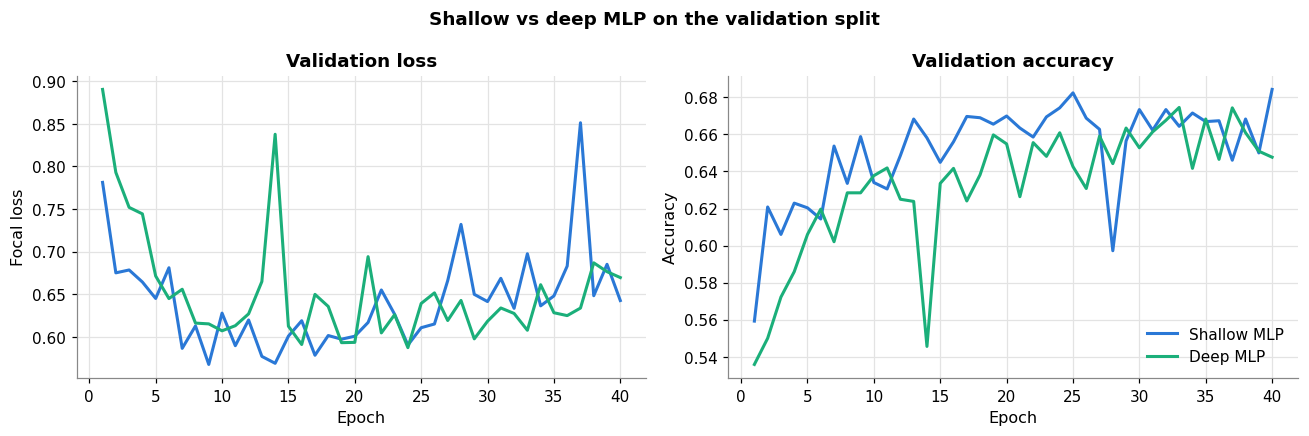

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), sharex=True)
for name, (dims, best, hist), color in [("Shallow MLP", model_info["Shallow MLP"], TRAIN_COLOR),
                                         ("Deep MLP", model_info["Deep MLP"], "#1baf7a")]:
    epochs = range(1, len(hist["val_loss"]) + 1)
    axes[0].plot(epochs, hist["val_loss"], color=color, label=name)
    axes[1].plot(epochs, hist["val_acc"], color=color, label=name)
axes[0].set(title="Validation loss", xlabel="Epoch", ylabel=LOSS_NAMES[BEST_LOSS])
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend(loc="lower right")
fig.suptitle("Shallow vs deep MLP on the validation split", fontweight="bold")
fig.tight_layout()
plt.show()

**Reading the curves.** The shallow MLP's training accuracy reaches 85 % while validation levels
off near 68 %, a growing gap that shows over-fitting, which best-validation checkpointing keeps out
of the test results. The deep MLP learns more slowly (76 % training accuracy after 40 epochs) and
over-fits less, but never catches up on validation. Both validation curves are noisy, so selecting
the best checkpoint rather than the last epoch matters here.

## 11. Summary

In [25]:
summary = OrderedDict([
    ("Data split (train / val / test)", " / ".join(f"{len(loaders[k].dataset):,}" for k in ["train", "val", "test"])),
    ("Regularization strength (L2 weight decay)", f"{WEIGHT_DECAY:g}  (+ dropout 0.3)"),
    ("Best loss function (3 × 3 study)", LOSS_NAMES[BEST_LOSS]),
    ("Best optimizer (3 × 3 study)", OPT_NAMES[BEST_OPT]),
    ("Best learning rate (4-value study)", f"{BEST_LR:g}"),
    ("Shallow MLP — test accuracy / macro-F1",
     f"{test_results['Shallow MLP']['acc']:.4f} / {test_results['Shallow MLP']['macro_f1']:.4f}"),
    ("Deep MLP — test accuracy / macro-F1",
     f"{test_results['Deep MLP']['acc']:.4f} / {test_results['Deep MLP']['macro_f1']:.4f}"),
])
pd.DataFrame.from_dict(summary, orient="index", columns=["result"])

,result
Data split (train / val / test),"17,280 / 4,320 / 5,400"
Regularization strength (L2 weight decay),0 (+ dropout 0.3)
Best loss function (3 × 3 study),Focal loss
Best optimizer (3 × 3 study),RMSprop
Best learning rate (4-value study),0.001
Shallow MLP — test accuracy / macro-F1,0.6867 / 0.6812
Deep MLP — test accuracy / macro-F1,0.6693 / 0.6620


### Conclusions

The best MLP setup is focal loss + RMSprop at a learning rate of 1e-3 with dropout 0.3, and the
**shallow MLP is the better model: 68.7 % test accuracy / 0.681 macro-F1, against 66.9 % / 0.662
for the deep one**. Both plateau near 68 % because flattening the image discards spatial
structure, which motivates the convolutional networks in the next milestone.